# 02 Pace gap of the strongest teams

This notebook compares the recent pace of the three teams that scored most points before the cost cap with the pace of all the other teams. It uses `team_pace3` from the model table, so it is the same pace measure the model uses. It needs `data/processed/model_table.csv`, which is made by notebook 04.

## Setup

In [1]:
import sys
from pathlib import Path

# find the project folder, wherever the notebook is started from
cwd = Path.cwd()
root = next(p for p in [cwd, cwd / "AdvanceData", *cwd.parents] if (p / "src").is_dir())
sys.path.insert(0, str(root / "src"))

import competitiveness
import data_checks
import plots
import modeling

## The three strongest teams before 2021

Teams are ranked by their average final points in the seasons before 2021.

In [2]:
final = competitiveness.load_final_standings()
top_teams = competitiveness.strongest_teams(final)
print("Three strongest teams before 2021:", top_teams)

Three strongest teams before 2021: ['Mercedes', 'Ferrari', 'Red Bull']


## Pace gap by season

`team_pace3` is the average gap to the fastest team, in percent, over the team's previous three races. Lower means faster, and 0 means the team was the fastest. For each season the table gives the average of the strongest three teams, the average of all the others, and the difference between them.

In [3]:
data = modeling.load_model_table()
pace = competitiveness.pace_gap_by_group(data, top_teams)
display(pace)
plots.save_table(pace, "pace_gap_by_group.csv")

group,All other teams,Three strongest teams before 2021,difference
year,,,
2014,2.35,0.55,1.80
2015,2.21,0.74,1.47
2016,2.76,0.66,2.10
2017,2.71,0.60,2.11
2018,2.39,0.25,2.14
2019,2.38,0.42,1.96
2020,1.96,0.69,1.26
2021,2.07,0.59,1.49
2022,2.25,0.42,1.83


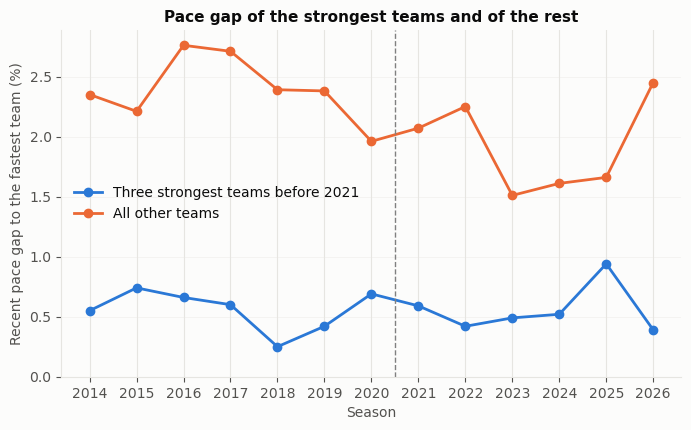

In [4]:
fig = plots.plot_pace_gap_by_group(pace, competitiveness.TOP_LABEL, competitiveness.OTHER_LABEL)
plots.save_figure(fig, "pace_gap_by_group.png")

*Figure.* Average recent pace gap to the fastest team, in percent of a lap time, for the three strongest teams before 2021 and for all other teams. Lower is faster. The grey dashed line marks the first season with the cost cap. The values for 2025 and 2026 are shown for completeness: 2026 is the first season with new technical rules.